# 01 — Train/val data audit (no test data)
Recomputes split checks and class-imbalance statistics from the manifests and a few real images; findings feed the proposal.

In [1]:
import os, json, subprocess, sys
HOME=os.path.expanduser('~'); ROOT=f'{HOME}/brain-mri-segmentation'; PROJ=ROOT; DATA=f'{ROOT}/data'; RUNS=f'{ROOT}/runs'
os.chdir(ROOT)
sys.path.insert(0, f'{PROJ}/src')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from lggseg.data import read_image, read_mask
tr=pd.read_csv(f'{DATA}/train_manifest.csv'); va=pd.read_csv(f'{DATA}/val_manifest.csv')
print(len(tr), tr.patient_id.nunique(), len(va), va.patient_id.nunique())
print('patient overlap:', len(set(tr.patient_id)&set(va.patient_id)))

2763 77 598 17
patient overlap: 0


In [2]:
for n,d in [('train',tr),('val',va)]:
    pos=d[d.has_foreground==1]
    print(n,'positive',len(pos),'empty',(d.has_foreground==0).sum(),'fg pixel frac %.4f'%(d.foreground_pixels.sum()/(len(d)*65536)))
    print('  lesion px quantiles', pos.foreground_pixels.quantile([0,.1,.25,.5,.75,.9,1]).round(0).tolist())

train positive 969 empty 1794 fg pixel frac 0.0106
  lesion px quantiles [23.0, 336.0, 757.0, 1584.0, 2863.0, 4182.0, 7683.0]
val positive 204 empty 394 fg pixel frac 0.0081
  lesion px quantiles [7.0, 206.0, 539.0, 1148.0, 2154.0, 3370.0, 6411.0]


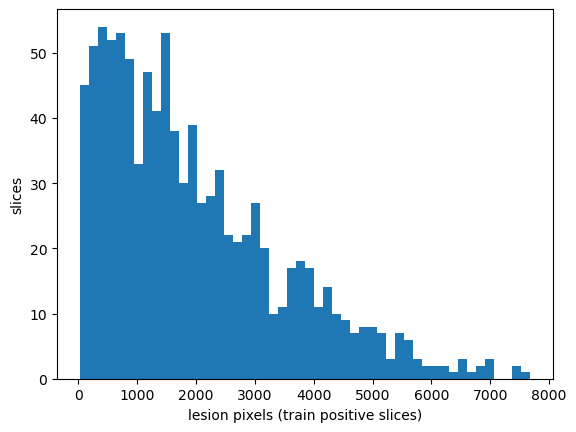

In [3]:
plt.hist(tr[tr.has_foreground==1].foreground_pixels,bins=50); plt.xlabel('lesion pixels (train positive slices)'); plt.ylabel('slices'); plt.show()

In [4]:
# channel statistics on a train sample (train only)
samp=tr.sample(200,random_state=0)
X=np.stack([read_image(f'{DATA}/'+p) for p in samp.image_path])
for c,name in enumerate(['pre-contrast','FLAIR','post-contrast']): print(name, X[...,c].mean().round(2), X[...,c].std().round(2))

pre-contrast 21.64 32.95
FLAIR 19.83 30.54
post-contrast 21.17 32.26


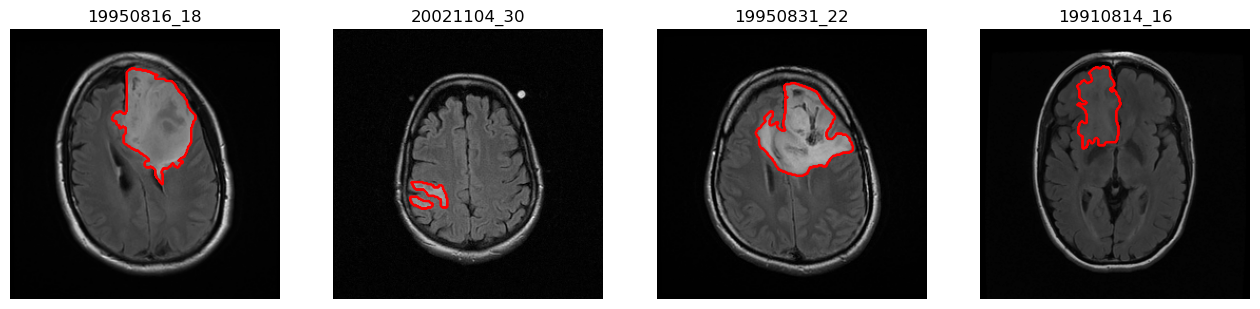

In [5]:
# visual check: 4 positive train slices with mask overlay
rows=tr[tr.has_foreground==1].sample(4,random_state=1)
fig,ax=plt.subplots(1,4,figsize=(16,4))
for a,(_,r) in zip(ax,rows.iterrows()):
    im=read_image(f'{DATA}/'+r.image_path); m=read_mask(f'{DATA}/'+r.mask_path)
    a.imshow(im[...,1],cmap='gray'); a.contour(m,colors='r',linewidths=1); a.set_title(r.slice_id); a.axis('off')
plt.show()